In [1]:
from pathlib import Path
import gzip
import shutil
import json
import time
import random
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.utils import make_grid, save_image
import matplotlib.pyplot as plt

SEED = 42
LATENT_DIM, NUM_CLASSES, IMG_SIZE = 100, 10, 32
IMG_DIM = 28 * 28
BATCH_SIZE = 128
LR = 2e-4
BASELINE_EPOCHS = 10
CONDITIONAL_EPOCHS = 10
SMOKE_TEST = True

TRAIN_LIMIT = None
OFFLINE_MNIST_DIR = None
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
WORK_DIR = Path('/kaggle/working') if Path('/kaggle/working').is_dir() else Path.cwd()
DATA_DIR = WORK_DIR / 'data'
OUTPUT_DIR = WORK_DIR / 'gan_lab_student'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def seed_all(seed):
    random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_all(SEED)
print('Device:', DEVICE, '| Smoke mode:', SMOKE_TEST)
print('Outputs:', OUTPUT_DIR.resolve())


Device: cuda | Smoke mode: True
Outputs: /content/gan_lab_student


In [2]:
class VanillaGenerator(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM, img_dim=IMG_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 1024),
            nn.LeakyReLU(0.2),
            nn.Linear(1024, img_dim),
            nn.Tanh()
        )

    def forward(self, z):
        return self.net(z)





class VanillaDiscriminator(nn.Module):
    def __init__(self, img_dim=IMG_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(img_dim, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 1),
        )

    def forward(self, x):
        return self.net(x)


In [3]:
criterion = nn.BCEWithLogitsLoss()

def generate(g, z, labels=None):
    return g(z) if labels is None else g(z, labels)

def discriminate(d, images, labels=None):
    return d(images) if labels is None else d(images, labels)

def discriminator_step(g, d, opt_g, opt_d, real, labels=None):
    g.train()
    d.train()
    opt_d.zero_grad(set_to_none=True)
    z = torch.randn(real.size(0), LATENT_DIM, device=real.device, dtype=real.dtype)
    with torch.no_grad():
        fake = generate(g, z, labels)
    real_logits = discriminate(d, real, labels).reshape(-1)
    fake_logits = discriminate(d, fake.detach(), labels).reshape(-1)
    loss = criterion(real_logits, torch.ones_like(real_logits)) + criterion(fake_logits, torch.zeros_like(fake_logits))
    loss.backward()
    opt_d.step()
    return float(loss.detach())

def generator_step(g, d, opt_g, opt_d, batch_size, labels=None):
    g.train()
    opt_g.zero_grad(set_to_none=True)
    opt_d.zero_grad(set_to_none=True)
    previous_mode = d.training
    d.requires_grad_(False)
    d.eval()
    try:
        z = torch.randn(batch_size, LATENT_DIM, device=next(g.parameters()).device)
        fake = generate(g, z, labels)
        logits = discriminate(d, fake, labels).reshape(-1)
        loss = criterion(logits, torch.ones_like(logits))
        loss.backward()
        opt_g.step()
        return float(loss.detach())
    finally:
        d.requires_grad_(True)
        d.train(previous_mode)


In [4]:
def snapshot(module):
    return {k: v.detach().clone() for k, v in module.state_dict().items()}

def check_updates(g, d, real, labels=None):
    opt_g = torch.optim.Adam(g.parameters(), lr=LR, betas=(0.5, 0.999))
    opt_d = torch.optim.Adam(d.parameters(), lr=LR, betas=(0.5, 0.999))
    before_g = {k: p.detach().clone() for k, p in g.named_parameters()}
    before_d = {k: p.detach().clone() for k, p in d.named_parameters()}
    dl = discriminator_step(g, d, opt_g, opt_d, real, labels)
    assert all(torch.equal(before_g[k], p) for k, p in g.named_parameters()), 'G updated in D step'
    assert all(p.grad is None for p in g.parameters()), 'Detach fakes in D step'
    assert any(not torch.equal(before_d[k], p) for k, p in d.named_parameters()), 'D did not update'
    d_state = snapshot(d)
    gl = generator_step(g, d, opt_g, opt_d, real.size(0), labels)
    assert any(not torch.equal(before_g[k], p) for k, p in g.named_parameters()), 'G did not update'
    assert all(torch.equal(d_state[k], v) for k, v in d.state_dict().items()), 'D changed in G step'
    assert all(p.grad is None for p in d.parameters()), 'D gradients should remain disabled'
    assert torch.isfinite(torch.tensor([dl, gl])).all()
    print('Update checks passed:', {'D': dl, 'G': gl})

seed_all(SEED)
check_updates(VanillaGenerator().to(DEVICE), VanillaDiscriminator().to(DEVICE),
              torch.rand(4, IMG_DIM, device=DEVICE) * 2 - 1)


Update checks passed: {'D': 1.3750903606414795, 'G': 0.682660698890686}


100%|██████████| 9.91M/9.91M [00:00<00:00, 57.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.64MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 14.5MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.82MB/s]


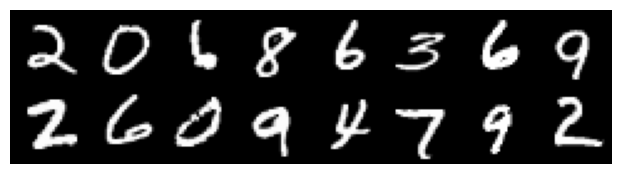

Training examples: 256


In [5]:
raw_dir = DATA_DIR / "MNIST" / "raw"
raw_dir.mkdir(parents=True, exist_ok=True)
input_dir = Path(OFFLINE_MNIST_DIR) if OFFLINE_MNIST_DIR is not None else Path("/kaggle/input")
raw_names = [
    "train-images-idx3-ubyte", "train-labels-idx1-ubyte",
    "t10k-images-idx3-ubyte", "t10k-labels-idx1-ubyte",
]
for name in raw_names:
    destination = raw_dir / name
    if destination.exists() or not input_dir.exists():
        continue
    aliases = [name, name.replace("-idx", ".idx")]
    candidates = sorted({path for alias in aliases
                         for pattern in (alias, alias + ".gz")
                         for path in input_dir.rglob(pattern) if path.is_file()})
    if candidates:
        source = candidates[0]
        opener = gzip.open if source.suffix == ".gz" else open
        with opener(source, "rb") as src, destination.open("wb") as dst:
            shutil.copyfileobj(src, dst)
        print("Loaded attached file:", source)

def load_mnist(size):
    transform = transforms.Compose([
        transforms.Resize(size), transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,)),
    ])
    try:
        return datasets.MNIST(str(DATA_DIR), train=True, download=False, transform=transform)
    except RuntimeError:
        try:
            return datasets.MNIST(str(DATA_DIR), train=True, download=True, transform=transform)
        except Exception as exc:
            raise RuntimeError('MNIST unavailable. Enable internet or supply original IDX files '
                               'using OFFLINE_MNIST_DIR (Kaggle: attach under /kaggle/input).') from exc

def make_loader(size):
    dataset = load_mnist(size)
    limit = 2 * BATCH_SIZE if SMOKE_TEST else TRAIN_LIMIT
    if limit is not None:
        assert isinstance(limit, int) and limit >= 2, 'Use at least two examples'
        indices = torch.randperm(len(dataset), generator=torch.Generator().manual_seed(SEED))
        dataset = Subset(dataset, indices[:min(limit, len(dataset))].tolist())
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
                      generator=torch.Generator().manual_seed(SEED),
                      pin_memory=(DEVICE.type == 'cuda'))

preview_loader = make_loader(28)
real_images, real_labels = next(iter(preview_loader))
assert real_images.shape[1:] == (1, 28, 28)
assert -1 <= real_images.min() and real_images.max() <= 1
plt.figure(figsize=(8, 2))
plt.imshow(make_grid((real_images[:16] + 1) / 2, nrow=8).permute(1, 2, 0))
plt.axis('off')
plt.show()
print('Training examples:', len(preview_loader.dataset))


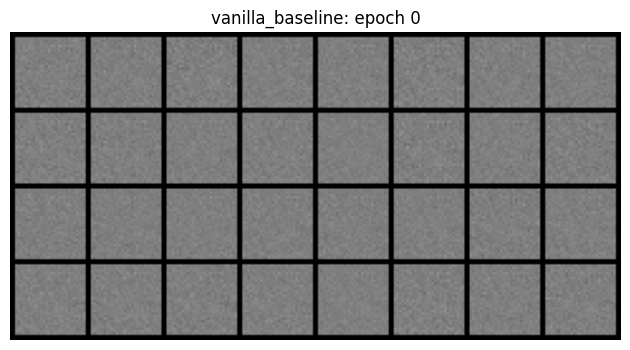

vanilla_baseline 1/1 | D=1.2905 G=0.6764


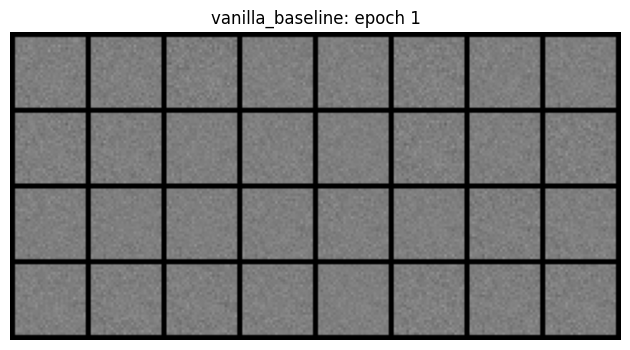

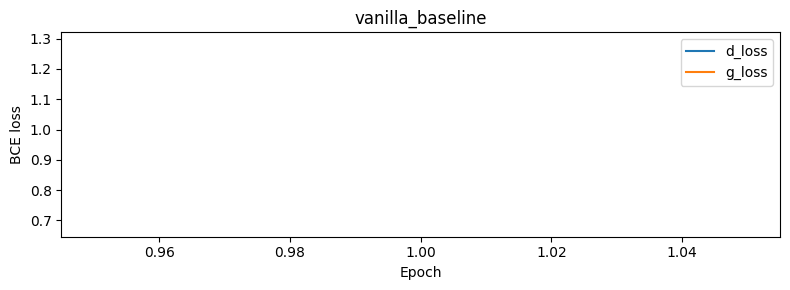

In [6]:
@torch.no_grad()
def sample(g, noise, labels=None):
    previous_mode = g.training
    g.eval()
    try:
        images = generate(g, noise, labels)
        if images.ndim == 2:
            images = images.reshape(-1, 1, 28, 28)
        return ((images.cpu() + 1) / 2).clamp(0, 1)
    finally:
        g.train(previous_mode)

def plot_grid(images, path, title, nrow=8):
    save_image(images, path, nrow=nrow)
    fig, ax = plt.subplots(figsize=(8, 8 if len(images) == 80 else 4))
    ax.imshow(make_grid(images, nrow=nrow).permute(1, 2, 0), vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis('off')
    plt.show()
    plt.close(fig)

def run_experiment(name, conditional=False, d_lr_multiplier=1.0):
    seed_all(SEED)
    folder = OUTPUT_DIR / name
    folder.mkdir(parents=True, exist_ok=True)
    if conditional:
        g = ConditionalGenerator().to(DEVICE).apply(weights_init)
        d = ConditionalDiscriminator().to(DEVICE).apply(weights_init)
    else:
        g, d = VanillaGenerator().to(DEVICE), VanillaDiscriminator().to(DEVICE)
    opt_g = torch.optim.Adam(g.parameters(), lr=LR, betas=(0.5, 0.999))
    opt_d = torch.optim.Adam(d.parameters(), lr=LR * d_lr_multiplier, betas=(0.5, 0.999))
    loader = make_loader(32 if conditional else 28)
    epochs = 1 if SMOKE_TEST else (CONDITIONAL_EPOCHS if conditional else BASELINE_EPOCHS)
    sample_rng = torch.Generator().manual_seed(SEED + 1)
    if conditional:
        fixed_z = torch.randn(8, LATENT_DIM, generator=sample_rng).repeat(10, 1).to(DEVICE)
        fixed_y = torch.arange(10, device=DEVICE).repeat_interleave(8)
    else:
        fixed_z = torch.randn(32, LATENT_DIM, generator=sample_rng).to(DEVICE)
        fixed_y = None
    def record(epoch):
        title = f'{name}: epoch {epoch}'
        if conditional:
            title += ' | requested digits 0–9 from top to bottom'
        plot_grid(sample(g, fixed_z, fixed_y), folder / f'epoch_{epoch:03d}.png', title)
    record(0)
    history = {'d_loss': [], 'g_loss': []}
    started = time.perf_counter()
    for epoch in range(1, epochs + 1):
        d_total = g_total = seen = 0
        for images, labels in loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE) if conditional else None
            if not conditional:
                images = images.flatten(1)
            dl = discriminator_step(g, d, opt_g, opt_d, images, labels)
            gl = generator_step(g, d, opt_g, opt_d, len(images), labels)
            assert torch.isfinite(torch.tensor([dl, gl])).all(), 'Non-finite loss'
            d_total += dl * len(images)
            g_total += gl * len(images)
            seen += len(images)
        history['d_loss'].append(d_total / seen)
        history['g_loss'].append(g_total / seen)
        print(f"{name} {epoch}/{epochs} | D={d_total/seen:.4f} G={g_total/seen:.4f}")
        if epoch == 1 or epoch % 5 == 0 or epoch == epochs:
            record(epoch)
    elapsed = time.perf_counter() - started
    config = dict(name=name, conditional=conditional, seed=SEED, latent_dim=LATENT_DIM,
                  num_classes=NUM_CLASSES, image_size=32 if conditional else 28,
                  batch_size=BATCH_SIZE, g_lr=LR, d_lr=LR*d_lr_multiplier,
                  epochs=epochs, training_examples=len(loader.dataset), smoke_test=SMOKE_TEST,
                  train_limit=TRAIN_LIMIT, device=str(DEVICE))
    torch.save(dict(generator=g.state_dict(), discriminator=d.state_dict(),
                    optimizer_g=opt_g.state_dict(), optimizer_d=opt_d.state_dict(),
                    config=config, history=history), folder / 'checkpoint.pt')
    (folder / 'results.json').write_text(json.dumps(
        dict(config=config, history=history, elapsed_seconds=elapsed), indent=2))
    fig, ax = plt.subplots(figsize=(8, 3))
    for key, values in history.items():
        ax.plot(range(1, epochs + 1), values, label=key)
    ax.set(xlabel='Epoch', ylabel='BCE loss', title=name)
    ax.legend()
    fig.tight_layout()
    fig.savefig(folder / 'losses.png')
    plt.show()
    plt.close(fig)
    return dict(generator=g, discriminator=d, history=history, folder=folder,
                config=config, elapsed_seconds=elapsed, fixed_z=fixed_z, fixed_y=fixed_y)

baseline = run_experiment('vanilla_baseline')


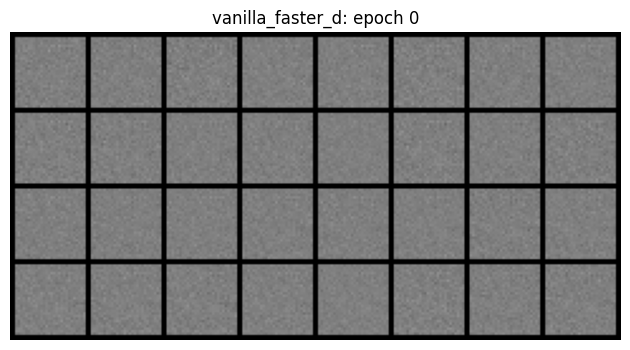

vanilla_faster_d 1/1 | D=1.1056 G=0.6735


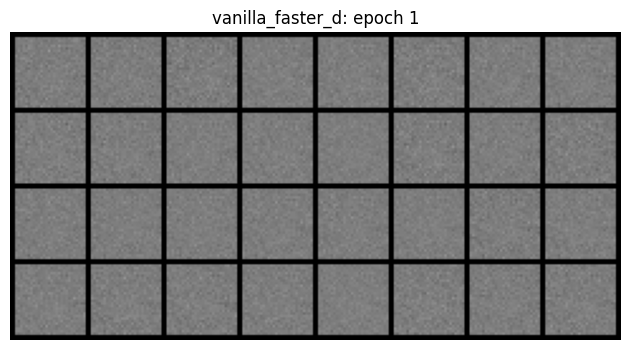

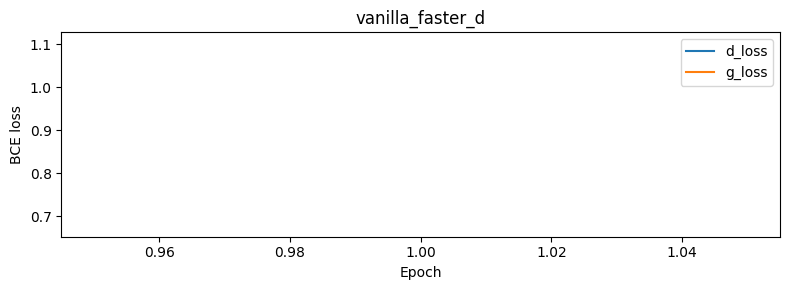

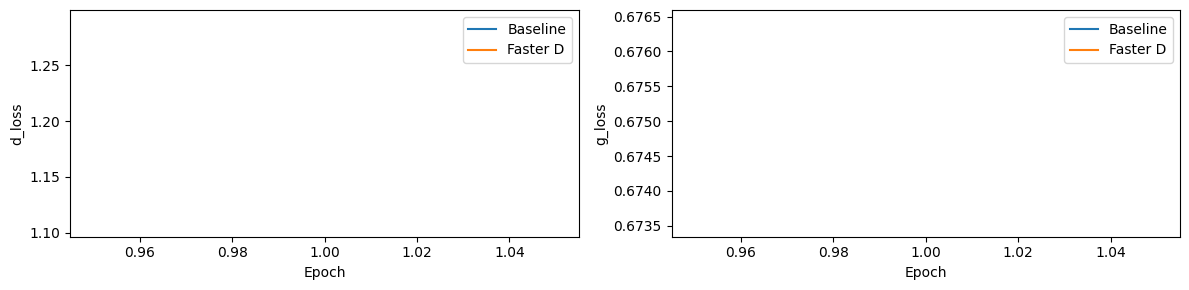

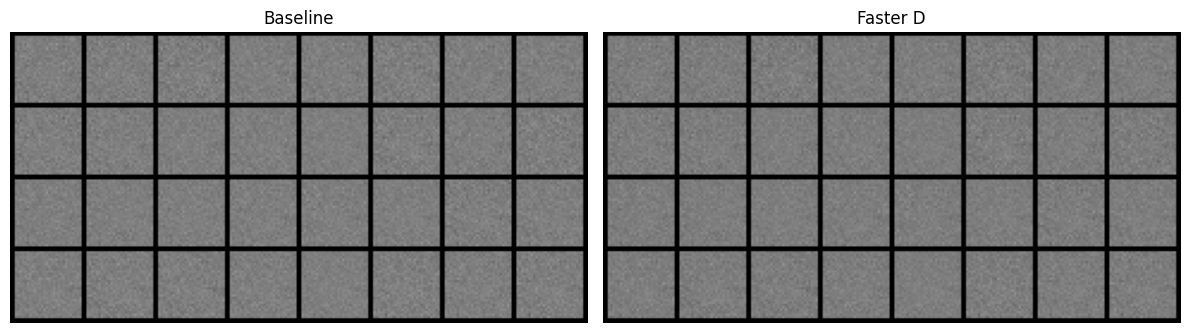

In [7]:
intervention = run_experiment('vanilla_faster_d', d_lr_multiplier=5.0)

fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for ax, key in zip(axes, ['d_loss', 'g_loss']):
    for label, result in [('Baseline', baseline), ('Faster D', intervention)]:
        values = result['history'][key]
        ax.plot(range(1, len(values) + 1), values, label=label)
    ax.set(xlabel='Epoch', ylabel=key)
    ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'intervention_losses.png')
plt.show()
plt.close(fig)


fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, label, result in zip(axes, ['Baseline', 'Faster D'], [baseline, intervention]):
    images = sample(result['generator'], baseline['fixed_z'])
    ax.imshow(make_grid(images, nrow=8).permute(1, 2, 0))
    ax.set_title(label)
    ax.axis('off')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'intervention_samples.png')
plt.show()
plt.close(fig)


In [8]:
def condition_noise(noise, labels):
    one_hot = F.one_hot(labels.to(device=noise.device), num_classes=NUM_CLASSES).to(dtype=noise.dtype)
    return torch.cat((noise, one_hot), dim=1).view(noise.size(0), LATENT_DIM + NUM_CLASSES, 1, 1)

def condition_images(images, labels):
    one_hot = F.one_hot(labels.to(device=images.device), num_classes=NUM_CLASSES).to(dtype=images.dtype)
    maps = one_hot[:, :, None, None].expand(-1, -1, images.size(2), images.size(3))
    return torch.cat((images, maps), dim=1)


In [9]:
class ConditionalGenerator(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM, num_classes=NUM_CLASSES):
        super().__init__()
        self.num_classes = num_classes
        self.net = nn.Sequential(
            nn.ConvTranspose2d(latent_dim + num_classes, 256, 4, 1, 0, bias=False),
            nn.BatchNorm2d(256), nn.ReLU(True),
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128), nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(True),
            nn.ConvTranspose2d(64, 1, 4, 2, 1, bias=False),
            nn.Tanh(),
        )

    def forward(self, noise, class_labels):
        return self.net(condition_noise(noise, class_labels))


class ConditionalDiscriminator(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        self.num_classes = num_classes
        self.net = nn.Sequential(

            nn.Conv2d(in_channels=1 + num_classes, out_channels=64, kernel_size=4, stride=2, padding=1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128), nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(in_channels=128, out_channels=256, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(256), nn.LeakyReLU(0.2, inplace=True),


            nn.Conv2d(in_channels=256, out_channels=1, kernel_size=4, stride=1, padding=0, bias=False),
        )

    def forward(self, images, class_labels):
        return self.net(condition_images(images, class_labels)).flatten(1)


def weights_init(module):
    if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(module.weight, 0.0, 0.02)
    elif isinstance(module, nn.BatchNorm2d):
        nn.init.normal_(module.weight, 1.0, 0.02)
        nn.init.zeros_(module.bias)


Update checks passed: {'D': 1.5615860223770142, 'G': 0.6684980392456055}


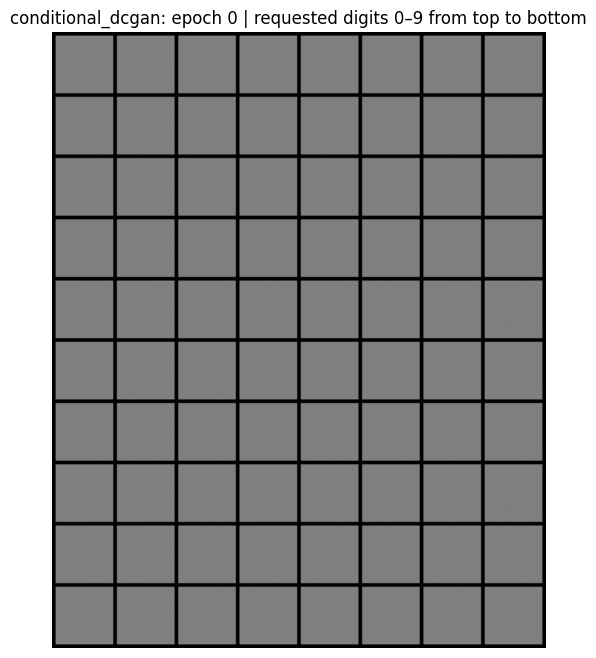

conditional_dcgan 1/1 | D=1.3247 G=0.6737


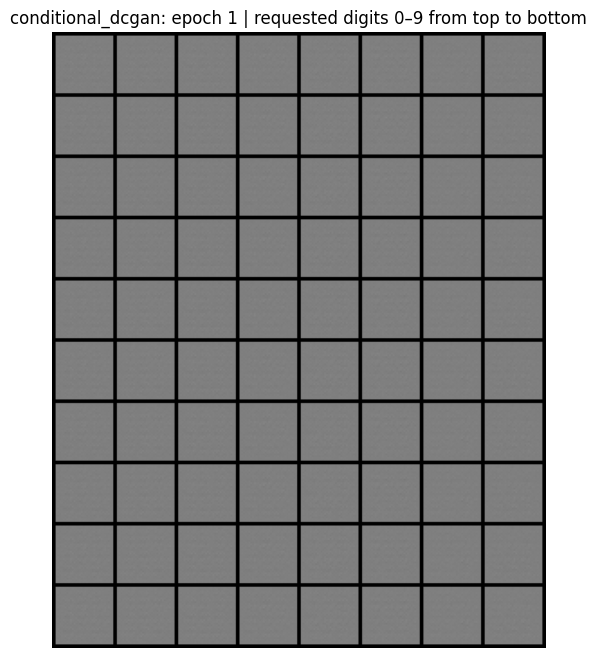

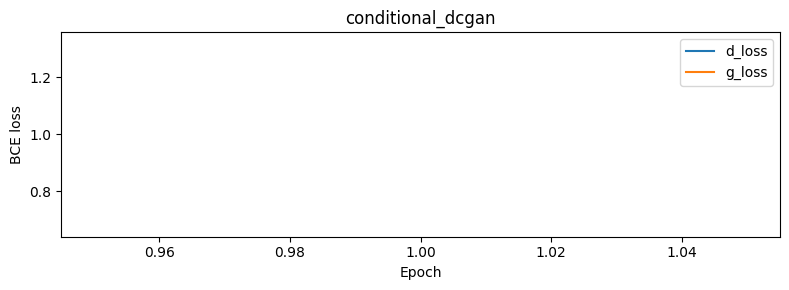

In [10]:
seed_all(SEED)
labels = torch.tensor([0, 3, 7, 9], device=DEVICE)
noise = torch.randn(4, LATENT_DIM, device=DEVICE)
images = torch.rand(4, 1, IMG_SIZE, IMG_SIZE, device=DEVICE) * 2 - 1
conditioned_z = condition_noise(noise, labels)
conditioned_x = condition_images(images, labels)
expected = F.one_hot(labels, NUM_CLASSES).float()
assert conditioned_z.shape == (4, LATENT_DIM + NUM_CLASSES, 1, 1)
assert torch.equal(conditioned_z[:, :LATENT_DIM, 0, 0], noise)
assert torch.equal(conditioned_z[:, LATENT_DIM:, 0, 0], expected)
assert conditioned_x.shape == (4, 11, IMG_SIZE, IMG_SIZE)
assert torch.equal(conditioned_x[:, :1], images)
assert torch.equal(conditioned_x[:, 1:], expected[:, :, None, None].expand(-1, -1, IMG_SIZE, IMG_SIZE))
test_g = ConditionalGenerator().to(DEVICE).apply(weights_init)
test_d = ConditionalDiscriminator().to(DEVICE).apply(weights_init)
with torch.no_grad():
    generated = test_g(noise, labels)
    assert generated.shape == images.shape
    assert generated.min() >= -1 and generated.max() <= 1
    assert test_d(generated, labels).shape == (4, 1)
check_updates(test_g, test_d, images, labels)
del test_g, test_d

conditional = run_experiment('conditional_dcgan', conditional=True)


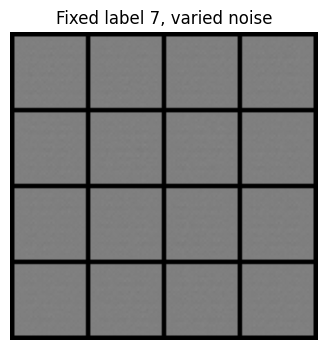

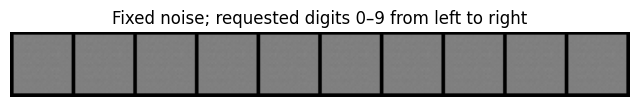

In [11]:
REQUESTED_DIGIT = 7
assert isinstance(REQUESTED_DIGIT, int) and 0 <= REQUESTED_DIGIT < NUM_CLASSES
probe_rng = torch.Generator().manual_seed(SEED + 2)
varying_z = torch.randn(16, LATENT_DIM, generator=probe_rng).to(DEVICE)
fixed_label = torch.full((16,), REQUESTED_DIGIT, dtype=torch.long, device=DEVICE)
plot_grid(sample(conditional['generator'], varying_z, fixed_label),
          conditional['folder'] / f'fixed_label_{REQUESTED_DIGIT}.png',
          f'Fixed label {REQUESTED_DIGIT}, varied noise', nrow=4)
fixed_z = torch.randn(1, LATENT_DIM, generator=probe_rng).repeat(10, 1).to(DEVICE)
varying_labels = torch.arange(NUM_CLASSES, device=DEVICE)
plot_grid(sample(conditional['generator'], fixed_z, varying_labels),
          conditional['folder'] / 'fixed_noise.png',
          'Fixed noise; requested digits 0–9 from left to right', nrow=10)


In [12]:

checkpoint_path = conditional['folder'] / 'checkpoint.pt'
checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
restored_g = ConditionalGenerator(
    latent_dim=checkpoint['config']['latent_dim'],
    num_classes=checkpoint['config']['num_classes'],
).to(DEVICE)
restored_g.load_state_dict(checkpoint['generator'])
restored_g.eval()
assert torch.allclose(sample(restored_g, fixed_z, varying_labels),
                      sample(conditional['generator'], fixed_z, varying_labels))
print('Checkpoint reload verified. Artifacts:', OUTPUT_DIR.resolve())


Checkpoint reload verified. Artifacts: /content/gan_lab_student
